# JiT-Inspired Diffusion on CIFAR-10

## 1. Environment Setup

In [ ]:
import os, math, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Dataset Download

In [ ]:
IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
train_dataset = datasets.CIFAR10("./data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                          drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)


100%|██████████| 170M/170M [31:03<00:00, 91.5kB/s]


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Dataset Visualization

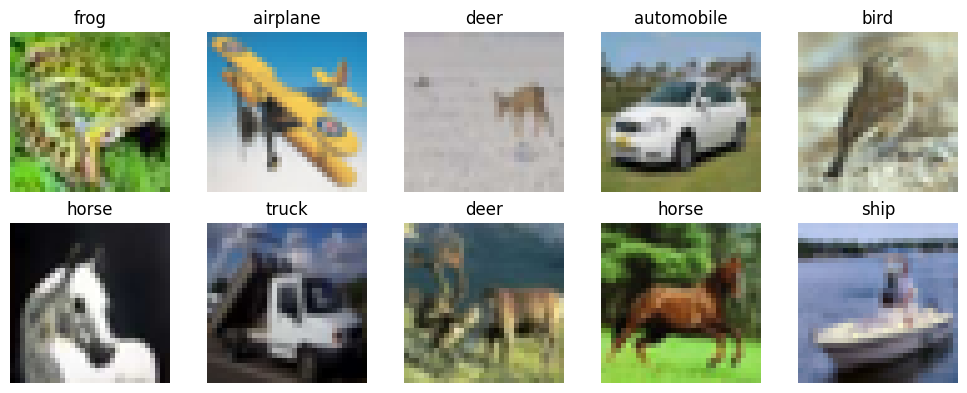

In [ ]:
def show_tensor_image(image):
    image = (image.detach().cpu().clamp(-1, 1) + 1) / 2
    return image.permute(1, 2, 0).numpy()

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(show_tensor_image(images[i]))
    ax.set_title(train_dataset.classes[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 4. JiT-Inspired Model

In [ ]:
class SmallJiT(nn.Module):
    def __init__(self, image_size=32, patch_size=4, in_channels=3,
                 embed_dim=128, depth=4, num_heads=4, mlp_dim=512):
        super().__init__()
        if image_size % patch_size:
            raise ValueError("image_size must be divisible by patch_size")
        self.image_size = image_size
        self.patch_size = patch_size
        self.grid_size = image_size // patch_size
        self.num_patches = self.grid_size ** 2
        self.patch_dim = patch_size * patch_size * in_channels
        self.embed_dim = embed_dim
        self.patch_embed = nn.Linear(self.patch_dim, embed_dim)
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches, embed_dim) * 0.02)
        self.time_mlp = nn.Sequential(nn.Linear(embed_dim, embed_dim), nn.SiLU(),
                                      nn.Linear(embed_dim, embed_dim))
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                    dim_feedforward=mlp_dim, activation="gelu", batch_first=True,
                    norm_first=False)
        self.transformer = nn.TransformerEncoder(layer, num_layers=depth)
        self.output_layer = nn.Linear(embed_dim, self.patch_dim)

    def time_embedding(self, t):
        half = self.embed_dim // 2
        freq = torch.exp(-math.log(10000) * torch.arange(
            half, device=t.device, dtype=torch.float32) / max(half - 1, 1))
        angles = t.float().reshape(-1, 1) * freq.reshape(1, -1)
        emb = torch.cat((torch.sin(angles), torch.cos(angles)), dim=1)
        if emb.shape[1] < self.embed_dim:
            emb = F.pad(emb, (0, self.embed_dim - emb.shape[1]))
        return self.time_mlp(emb)

    def forward(self, x, t):
        b, c, h, w = x.shape
        p = self.patch_size
        x = x.reshape(b, c, h // p, p, w // p, p)
        x = x.permute(0, 2, 4, 1, 3, 5).reshape(b, self.num_patches, self.patch_dim)
        x = self.patch_embed(x) + self.pos_embed + self.time_embedding(t).unsqueeze(1)
        x = self.output_layer(self.transformer(x))
        x = x.reshape(b, h // p, w // p, c, p, p)
        return x.permute(0, 3, 1, 4, 2, 5).reshape(b, c, h, w)

_check = SmallJiT(patch_size=4).to(device)
with torch.no_grad():
    _out = _check(torch.randn(2, 3, 32, 32, device=device), torch.rand(2, device=device))
print("Output shape:", tuple(_out.shape))
print("Patch-4 parameters:", f"{sum(p.numel() for p in _check.parameters()):,}")
del _check, _out


Output shape: (2, 3, 32, 32)
Patch-4 parameters: 846,768


## 5. Diffusion Training Loss

In [ ]:
def sample_time(batch_size, device):
    # Logit-normal time distribution inspired by the paper.
    return torch.sigmoid(torch.randn(batch_size, device=device) * 0.8 - 0.8).clamp(0.001, 0.995)

def diffusion_training_loss(model, clean_images):
    b = clean_images.shape[0]
    t = sample_time(b, clean_images.device)
    noise = torch.randn_like(clean_images)
    t_img = t.view(b, 1, 1, 1)
    z_t = t_img * clean_images + (1.0 - t_img) * noise
    x_pred = model(z_t, t)
    denom = (1.0 - t_img).clamp_min(0.05)
    v_target = (clean_images - z_t) / denom
    v_pred = (x_pred - z_t) / denom
    return F.mse_loss(v_pred, v_target)


## 6. Training Configuration

In [ ]:
EPOCHS = 10
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.01
PATCH_SIZES = [4, 8]
print("Epochs per model:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Patch sizes:", PATCH_SIZES)


Epochs per model: 10
Learning rate: 0.0001
Batch size: 128
Patch sizes: [4, 8]


## 7. Model Training

In [ ]:
def train_model(patch_size, epochs=EPOCHS):
    model = SmallJiT(patch_size=patch_size).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    losses = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        total, batches = 0.0, 0
        for images, _ in train_loader:
            images = images.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = diffusion_training_loss(model, images)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss: patch {patch_size}, epoch {epoch+1}")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item()
            batches += 1
        epoch_loss = total / max(batches, 1)
        losses.append(epoch_loss)
        print(f"Patch-{patch_size} | Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.6f} | "
              f"Elapsed: {(time.time()-start)/60:.2f} min")
    return model, losses

trained_models, training_histories = {}, {}
for patch_size in PATCH_SIZES:
    print(f"\nTraining Patch-{patch_size} model")
    trained_models[patch_size], training_histories[patch_size] = train_model(patch_size)
print("\nAll model training completed.")



Training Patch-4 model
Patch-4 | Epoch [1/10] | Loss: 0.358753 | Elapsed: 0.29 min
Patch-4 | Epoch [2/10] | Loss: 0.273627 | Elapsed: 0.58 min
Patch-4 | Epoch [3/10] | Loss: 0.256305 | Elapsed: 0.88 min
Patch-4 | Epoch [4/10] | Loss: 0.245600 | Elapsed: 1.17 min
Patch-4 | Epoch [5/10] | Loss: 0.239000 | Elapsed: 1.46 min
Patch-4 | Epoch [6/10] | Loss: 0.233386 | Elapsed: 1.75 min
Patch-4 | Epoch [7/10] | Loss: 0.223077 | Elapsed: 2.04 min
Patch-4 | Epoch [8/10] | Loss: 0.217640 | Elapsed: 2.33 min
Patch-4 | Epoch [9/10] | Loss: 0.214597 | Elapsed: 2.62 min
Patch-4 | Epoch [10/10] | Loss: 0.211430 | Elapsed: 2.91 min

Training Patch-8 model
Patch-8 | Epoch [1/10] | Loss: 0.432867 | Elapsed: 0.28 min
Patch-8 | Epoch [2/10] | Loss: 0.277711 | Elapsed: 0.57 min
Patch-8 | Epoch [3/10] | Loss: 0.259891 | Elapsed: 0.85 min
Patch-8 | Epoch [4/10] | Loss: 0.245296 | Elapsed: 1.12 min
Patch-8 | Epoch [5/10] | Loss: 0.234101 | Elapsed: 1.42 min
Patch-8 | Epoch [6/10] | Loss: 0.224155 | Elapsed: 

## 8. Training Loss Comparison

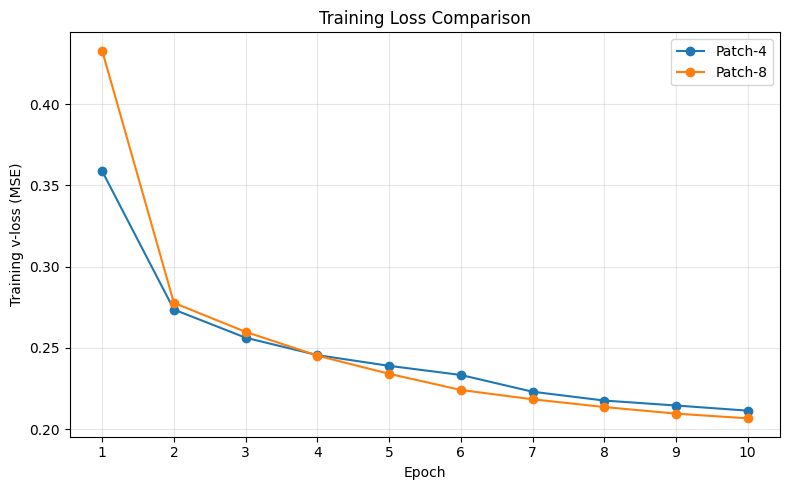

In [ ]:
plt.figure(figsize=(8, 5))
for p, losses in training_histories.items():
    plt.plot(range(1, len(losses)+1), losses, marker="o", label=f"Patch-{p}")
plt.xlabel("Epoch")
plt.ylabel("Training v-loss (MSE)")
plt.title("Training Loss Comparison")
plt.xticks(range(1, EPOCHS+1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 9. Test Evaluation

In [ ]:
@torch.no_grad()
def evaluate_model(model, max_batches=None):
    model.eval()
    total, count = 0.0, 0
    for i, (images, _) in enumerate(test_loader):
        if max_batches is not None and i >= max_batches:
            break
        images = images.to(device, non_blocking=True)
        total += diffusion_training_loss(model, images).item()
        count += 1
    return total / max(count, 1)

test_losses = {}
for p, trained_model in trained_models.items():
    test_losses[p] = evaluate_model(trained_model)
    print(f"Patch-{p} Test v-loss: {test_losses[p]:.6f}")


Patch-4 Test v-loss: 0.204914
Patch-8 Test v-loss: 0.201217


## 10. Diffusion Sampling

Sampling with Patch-4...
Sampling with Patch-8...


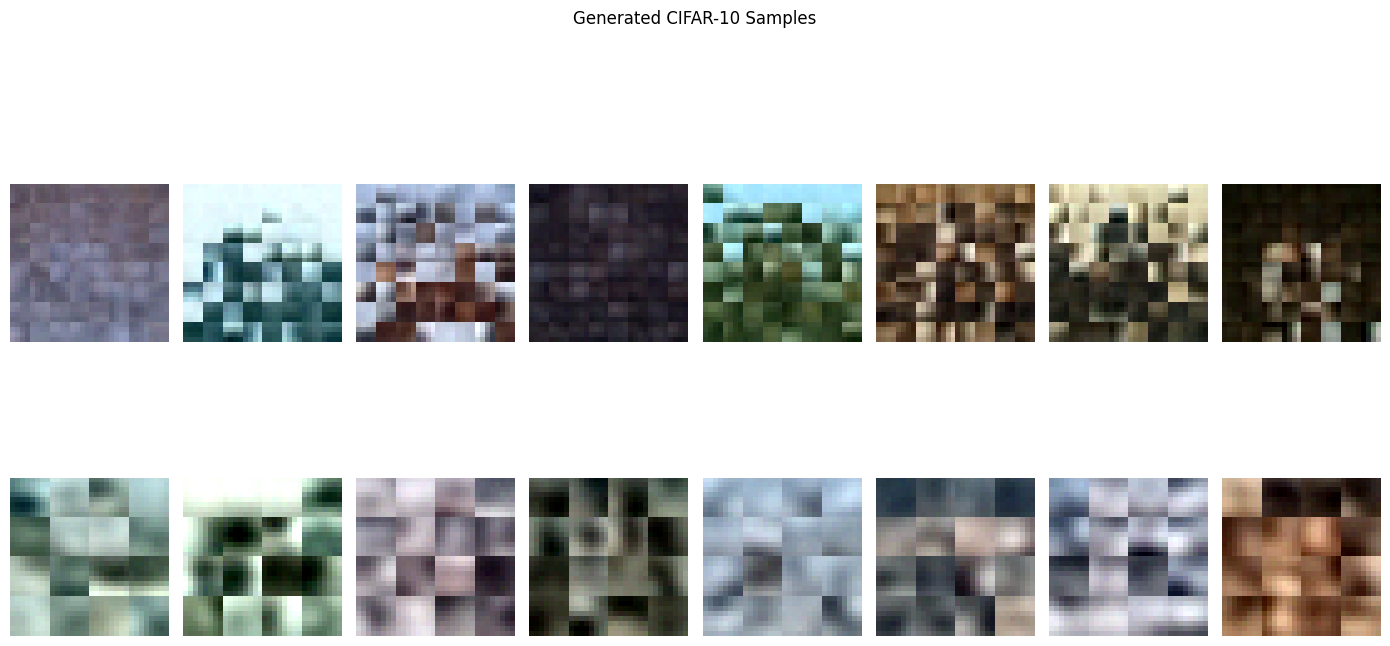

In [ ]:
@torch.no_grad()
def sample_images(model, num_images=8, steps=40):
    model.eval()
    z = torch.randn(num_images, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    grid = torch.linspace(0.0, 1.0, steps + 1, device=device)
    for i in range(steps):
        t_now, t_next = grid[i], grid[i+1]
        t_batch = torch.full((num_images,), t_now.item(), device=device)
        x_pred = model(z, t_batch)
        denom = (1.0 - t_now).clamp_min(0.05)
        v_pred = (x_pred - z) / denom
        z = z + (t_next - t_now) * v_pred
    return z.clamp(-1, 1)

sampled_images = {}
for p, trained_model in trained_models.items():
    print(f"Sampling with Patch-{p}...")
    sampled_images[p] = sample_images(trained_model, num_images=8, steps=40)

fig, axes = plt.subplots(len(PATCH_SIZES), 8, figsize=(14, 4 * len(PATCH_SIZES)))
if len(PATCH_SIZES) == 1:
    axes = np.expand_dims(axes, axis=0)
for row, p in enumerate(PATCH_SIZES):
    for col in range(8):
        axes[row, col].imshow(show_tensor_image(sampled_images[p][col]))
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(f"Patch-{p}", fontsize=12)
plt.suptitle("Generated CIFAR-10 Samples")
plt.tight_layout()
plt.show()


## 11. Denoising Visualization

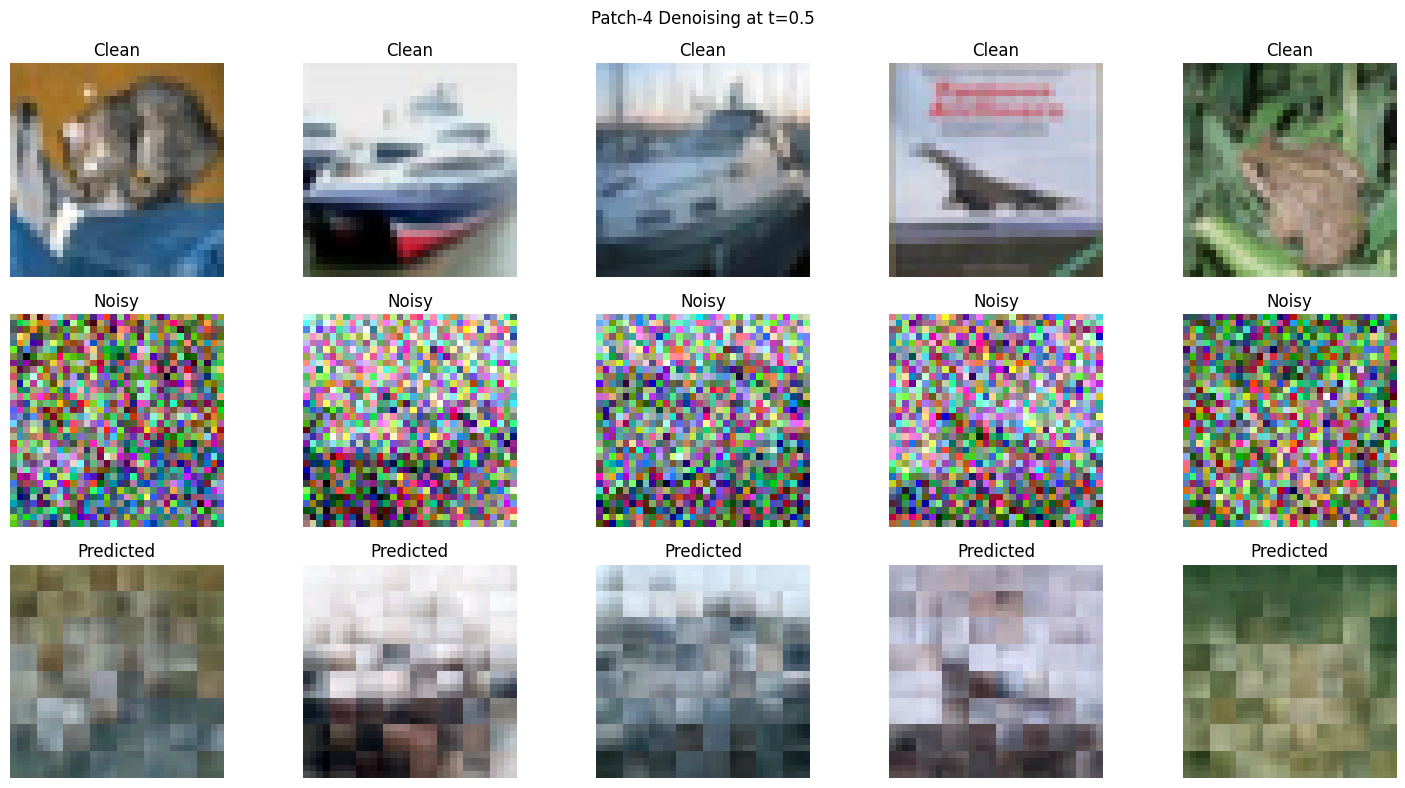

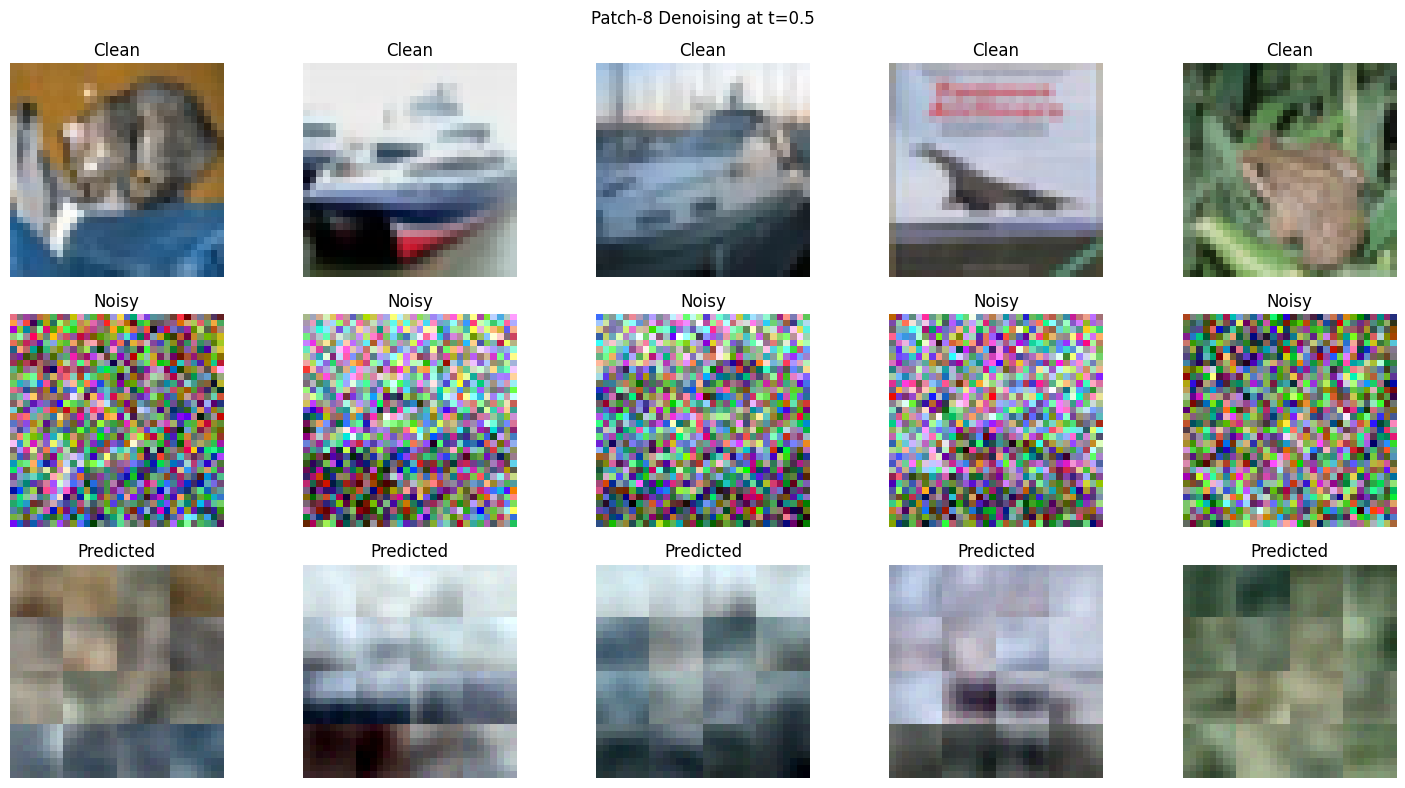

In [ ]:
@torch.no_grad()
def visualize_denoising(model, patch_size, num_images=5, t_value=0.5):
    model.eval()
    clean, _ = next(iter(test_loader))
    clean = clean[:num_images].to(device)
    noise = torch.randn_like(clean)
    t = torch.full((clean.shape[0],), t_value, device=device)
    t_img = t.view(-1, 1, 1, 1)
    noisy = t_img * clean + (1.0 - t_img) * noise
    predicted = model(noisy, t).clamp(-1, 1)

    fig, axes = plt.subplots(3, num_images, figsize=(3*num_images, 8))
    for i in range(num_images):
        axes[0, i].imshow(show_tensor_image(clean[i]))
        axes[0, i].set_title("Clean")
        axes[1, i].imshow(show_tensor_image(noisy[i]))
        axes[1, i].set_title("Noisy")
        axes[2, i].imshow(show_tensor_image(predicted[i]))
        axes[2, i].set_title("Predicted")
        for row in range(3):
            axes[row, i].axis("off")
    plt.suptitle(f"Patch-{patch_size} Denoising at t={t_value}")
    plt.tight_layout()
    plt.show()

visualize_denoising(trained_models[4], patch_size=4)
visualize_denoising(trained_models[8], patch_size=8)


## 12. Save Models

In [ ]:
os.makedirs("checkpoints", exist_ok=True)
for p, trained_model in trained_models.items():
    path = f"checkpoints/jit_cifar10_patch{p}.pth"
    torch.save({
        "model_state_dict": trained_model.state_dict(),
        "model_config": {"image_size": IMAGE_SIZE, "patch_size": p, "in_channels": 3,
                         "embed_dim": 128, "depth": 4, "num_heads": 4, "mlp_dim": 512},
        "training_losses": training_histories[p],
        "test_loss": test_losses[p],
    }, path)
    print("Saved:", path)


Saved: checkpoints/jit_cifar10_patch4.pth
Saved: checkpoints/jit_cifar10_patch8.pth


## 13. Final Results

In [ ]:
print("Final Results")
print("-" * 45)
for p in PATCH_SIZES:
    h = training_histories[p]
    print(f"Patch-{p}: initial train v-loss={h[0]:.6f}, final train v-loss={h[-1]:.6f}, "
          f"test v-loss={test_losses[p]:.6f}")
print("\nSmall-scale JiT-inspired CIFAR-10 experiment; not an exact reproduction of the paper's ImageNet-scale results.")


Final Results
---------------------------------------------
Patch-4: initial train v-loss=0.358753, final train v-loss=0.211430, test v-loss=0.204914
Patch-8: initial train v-loss=0.432867, final train v-loss=0.206700, test v-loss=0.201217

Small-scale JiT-inspired CIFAR-10 experiment; not an exact reproduction of the paper's ImageNet-scale results.


## 14. Without Time Embedding

In [ ]:
class SmallJiTNoTime(nn.Module):
    def __init__(
        self,
        image_size=32,
        patch_size=4,
        in_channels=3,
        embed_dim=128,
        depth=4,
        num_heads=4,
        mlp_dim=512
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size
        self.grid_size = image_size // patch_size
        self.num_patches = self.grid_size ** 2
        self.patch_dim = patch_size * patch_size * in_channels

        self.patch_embed = nn.Linear(self.patch_dim, embed_dim)

        self.pos_embed = nn.Parameter(
            torch.randn(1, self.num_patches, embed_dim) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=depth
        )

        self.output_layer = nn.Linear(
            embed_dim,
            self.patch_dim
        )

    def forward(self, x, t=None):
        batch_size, channels, height, width = x.shape
        p = self.patch_size

        x = x.reshape(
            batch_size, channels,
            height // p, p,
            width // p, p
        )

        x = x.permute(
            0, 2, 4, 1, 3, 5
        ).reshape(
            batch_size,
            self.num_patches,
            self.patch_dim
        )

        x = self.patch_embed(x) + self.pos_embed

        # Intentionally no time embedding
        x = self.transformer(x)
        x = self.output_layer(x)

        x = x.reshape(
            batch_size,
            height // p,
            width // p,
            channels,
            p, p
        )

        x = x.permute(
            0, 3, 1, 4, 2, 5
        ).reshape(
            batch_size, channels, height, width
        )

        return x


print("Ablation model created: Patch-4 without time embedding.")

Ablation model created: Patch-4 without time embedding.


In [ ]:
# Create the ablation model
ablation_model = SmallJiTNoTime(
    image_size=32,
    patch_size=4,
    in_channels=3,
    embed_dim=128,
    depth=4,
    num_heads=4,
    mlp_dim=512
).to(device)

# Optimizer
ablation_optimizer = torch.optim.AdamW(
    ablation_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Train the model
ablation_train_losses = []

print("Training Patch-4 without time embedding...")

for epoch in range(EPOCHS):
    ablation_model.train()
    total_loss = 0.0
    num_batches = 0

    for batch in train_loader:
        images = batch[0].to(device)

        ablation_optimizer.zero_grad()

        loss = diffusion_training_loss(
            ablation_model, images
        )

        loss.backward()
        ablation_optimizer.step()

        total_loss += loss.item()
        num_batches += 1

    epoch_loss = total_loss / num_batches
    ablation_train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"- Training Loss: {epoch_loss:.4f}"
    )

print("Ablation training completed!")

Training Patch-4 without time embedding...
Epoch [1/10] - Training Loss: 0.3765
Epoch [2/10] - Training Loss: 0.2761
Epoch [3/10] - Training Loss: 0.2576
Epoch [4/10] - Training Loss: 0.2472
Epoch [5/10] - Training Loss: 0.2421
Epoch [6/10] - Training Loss: 0.2380
Epoch [7/10] - Training Loss: 0.2317
Epoch [8/10] - Training Loss: 0.2230
Epoch [9/10] - Training Loss: 0.2195
Epoch [10/10] - Training Loss: 0.2163
Ablation training completed!


In [ ]:
# Evaluate the ablation model on test data

ablation_test_loss = evaluate_model(
    ablation_model,
    max_batches=None
)

print("\nAblation Study Results")
print("-" * 40)
print("Patch-4 without Time Embedding")
print(f"Final Training Loss: {ablation_train_losses[-1]:.6f}")
print(f"Test Loss: {ablation_test_loss:.6f}")


Ablation Study Results
----------------------------------------
Patch-4 without Time Embedding
Final Training Loss: 0.216322
Test Loss: 0.208269


ABLATION STUDY: RESULTS COMPARISON


,Experiment,Final Training Loss,Test Loss
0,Patch-4 (With Time Embedding),0.211430,0.204914
1,Patch-8 (With Time Embedding),0.206700,0.201217
2,Patch-4 (Without Time Embedding),0.216322,0.208269


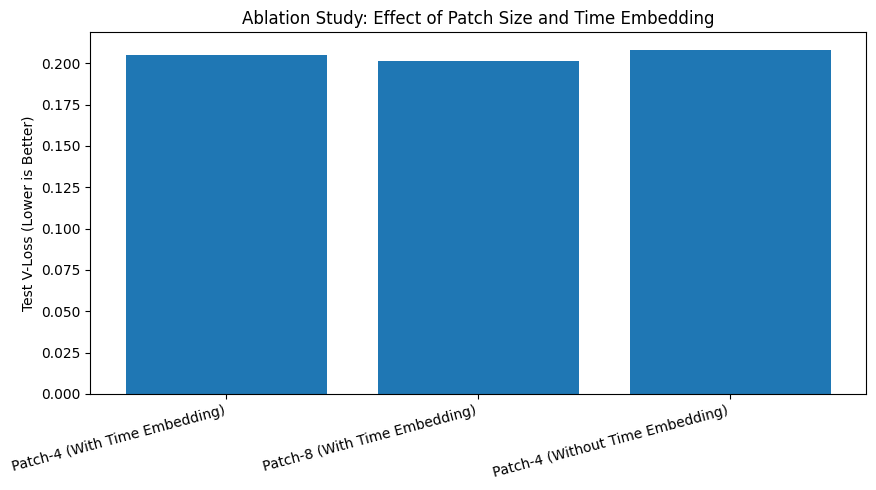

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Results from the original experiments and ablation study
ablation_results = pd.DataFrame({
    "Experiment": [
        "Patch-4 (With Time Embedding)",
        "Patch-8 (With Time Embedding)",
        "Patch-4 (Without Time Embedding)"
    ],
    "Final Training Loss": [
        0.211430,
        0.206700,
        ablation_train_losses[-1]
    ],
    "Test Loss": [
        0.204914,
        0.201217,
        ablation_test_loss
    ]
})

print("ABLATION STUDY: RESULTS COMPARISON")
display(ablation_results.round(6))

# Plot test losses
plt.figure(figsize=(9, 5))
plt.bar(
    ablation_results["Experiment"],
    ablation_results["Test Loss"]
)
plt.ylabel("Test V-Loss (Lower is Better)")
plt.title("Ablation Study: Effect of Patch Size and Time Embedding")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()